# 02 · Cleaning & exploratory analysis

<sub>Telco churn analysis &nbsp;|&nbsp; 01 Framing · **02 Cleaning & EDA** · 03 Hypothesis tests · 04 Modelling · 05 A/B test & ROI</sub>

**Goal:** fix the messy raw data (documenting every decision), then find where churn concentrates.

> **Key findings**
>
> - Month-to-month customers churn **15×** more than two-year customers (43 % vs 3 %).
> - **53 %** of customers in their first 6 months churn.
> - Electronic-check payers churn at ~**3×** the rate of auto-pay customers.
> - Online security / tech support customers churn ~**27 pts** less; streaming makes little difference.
> - Competitor offers are the most-cited reason for leaving.

In [1]:
import sys, warnings; from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from churn import config as C, style, charts
style.setup()

## Part A · Cleaning

All logic lives in `src/churn/data_cleaning.py`, so notebooks and the training pipeline clean data identically.

In [2]:
from churn.data_cleaning import load_raw, clean, churn_rate_table

raw = load_raw()
blank = pd.to_numeric(raw["Total Charges"], errors="coerce").isna()
style.card({"Raw shape": f"{raw.shape[0]:,} rows × {raw.shape[1]} columns",
          "Total Charges stored as": ", ".join(raw["Total Charges"].map(lambda v: type(v).__name__).unique()),
          "Blank Total Charges": f"{blank.sum()} (all with tenure = {raw.loc[blank, 'Tenure Months'].unique()[0]})",
          "'No internet service' rows": f"{(raw['Online Security'] == 'No internet service').sum():,} × 6 add-on columns",
          "Duplicate customer IDs": raw["CustomerID"].duplicated().sum()},
         caption="What's messy in the raw file")

Raw shape,"7,043 rows × 33 columns"
Total Charges stored as,"float, int, str"
Blank Total Charges,11 (all with tenure = 0)
'No internet service' rows,"1,526 × 6 add-on columns"
Duplicate customer IDs,0


In [3]:
df, log = clean(raw)
style.table(log[["step", "action", "reason", "rows_affected"]].set_index("step"),
          fmt={"rows_affected": "{:,.0f}"}, caption="Cleaning decision log")

,action,reason,rows_affected
step,,,
names,Converted to snake_case,Consistent attribute access in code,
duplicates,Checked customer_id,One row per customer is the unit of analysis,0
total_charges,Coerced to float; blanks set to 0,All 11 blanks have tenure 0: brand-new customers who have not been billed yet. Dropping them would bias against new customers; imputing a mean would invent revenue.,11
add-ons,Mapped to 'No' and added has_internet flag,"Otherwise the same fact is one-hot encoded 7 times, which creates perfect collinearity in the logistic regression","1,526"
multiple_lines,Mapped to 'No',phone_service already carries this,682
binary,Encoded as 0/1 integers,Lets churn rates be computed as means and models consume them directly,
features,"Added tenure_bucket (0-6, 7-12, 13-24, 25-48, 49-72) and n_addons",Buckets make the tenure effect readable in EDA; n_addons summarises service depth,
leakage,Kept in the clean table but excluded from model features,churn_score is IBM's own model output; churn_reason exists only for churners; churn_label duplicates the target; cltv is used for framing only,
constant,Dropped,No information,


In [4]:
# Post-cleaning checks: an exception here means the cleaning broke
assert df.total_charges.notna().all() and df.customer_id.is_unique
assert df.loc[df.has_internet == 0, C.ADDON_COLS].to_numpy().sum() == 0
ratio = (df.total_charges / (df.tenure_months * df.monthly_charges))[df.tenure_months > 0]
df.to_pickle(C.CLEAN_PATH)
print(f"✓ all checks passed · clean shape {df.shape} · total ≈ tenure × monthly (median ratio {ratio.median():.2f})")

✓ all checks passed · clean shape (7043, 32) · total ≈ tenure × monthly (median ratio 1.00)


## Part B · Where is churn concentrated?

Dashed line = overall churn rate (26.5 %). Whiskers = 95 % confidence intervals.

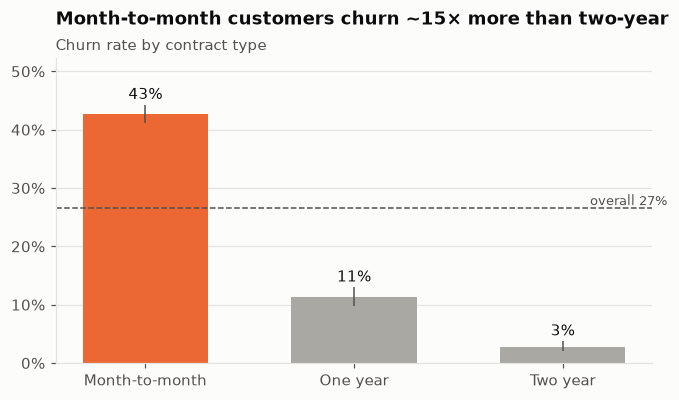

In [5]:
charts.churn_rate(df, "contract", "Month-to-month customers churn ~15× more than two-year",
                 "Churn rate by contract type", ["Month-to-month"], "02_contract");

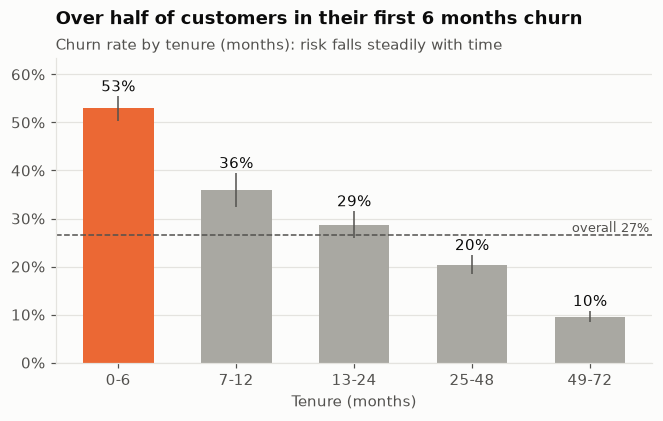

In [6]:
charts.churn_rate(df, "tenure_bucket", "Over half of customers in their first 6 months churn",
                 "Churn rate by tenure (months): risk falls steadily with time", ["0-6"], "02_tenure",
                 xlabel="Tenure (months)");

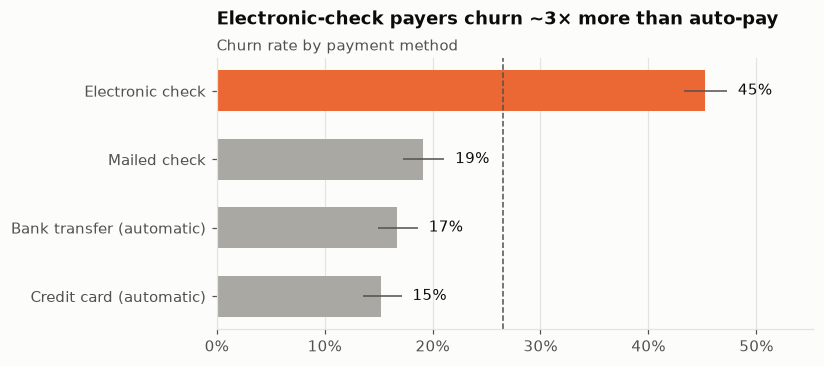

In [7]:
charts.churn_rate(df, "payment_method", "Electronic-check payers churn ~3× more than auto-pay",
                 "Churn rate by payment method", ["Electronic check"], "02_payment", horizontal=True);

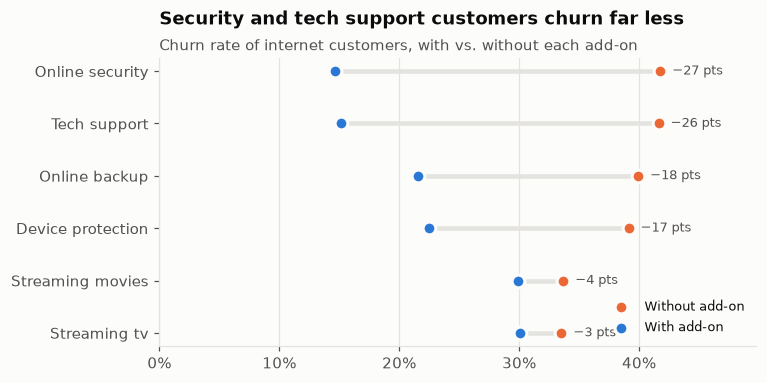

In [8]:
charts.addon_dumbbell(df);

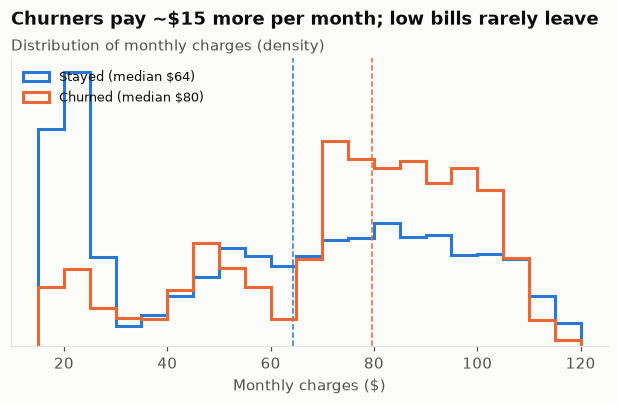

In [9]:
charts.charges_hist(df);

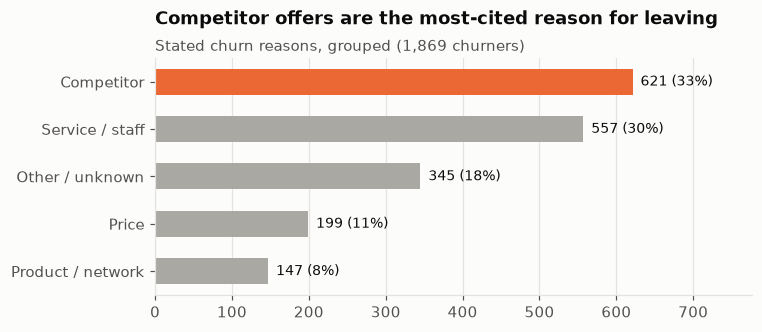

In [10]:
charts.churn_reasons(df);

## Claims to test in notebook 03

| # | Observation | Test |
|---|---|---|
| H1 | Month-to-month customers churn more than annual-contract customers | χ² + two-proportion CI |
| H2 | Churners pay higher monthly charges | Normality check → Mann-Whitney U |
| H3 | Fiber customers churn more than DSL customers | Two-proportion z, stratified by contract |
| H4 | E-check payers churn more than other payers | Two-proportion z, odds ratio |

> **Caution:** these factors overlap. Month-to-month customers are newer, more often on fiber and more often pay by e-check (table below). Single-factor views can't separate them; notebook 04 does.

In [11]:
overlap = pd.DataFrame({
    "fiber share": df.groupby("contract", observed=True)["internet_service"].apply(lambda s: (s == "Fiber optic").mean()),
    "e-check share": df.groupby("contract", observed=True)["payment_method"].apply(lambda s: (s == "Electronic check").mean()),
    "median tenure": df.groupby("contract", observed=True)["tenure_months"].median()})
style.table(overlap, fmt={"fiber share": "{:.0%}", "e-check share": "{:.0%}", "median tenure": "{:.0f} mo"},
          caption="Risk factors cluster in month-to-month customers")

,fiber share,e-check share,median tenure
contract,,,
Month-to-month,55%,48%,12 mo
One year,37%,24%,44 mo
Two year,25%,10%,64 mo
